In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [30]:
import os
import kagglehub
# import os

# Download latest version
path = kagglehub.dataset_download("dgomonov/new-york-city-airbnb-open-data")

print("Path to dataset files:", path)
df = os.path.join(path, "AB_NYC_2019.csv")
print("Path to dataset file:", df)
df = pd.read_csv(df)

Using Colab cache for faster access to the 'new-york-city-airbnb-open-data' dataset.
Path to dataset files: /kaggle/input/new-york-city-airbnb-open-data
Path to dataset file: /kaggle/input/new-york-city-airbnb-open-data/AB_NYC_2019.csv


In [31]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [33]:
df.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


In [34]:
df.shape

(48895, 16)

In [35]:
df.isnull().sum()

,0
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [36]:
df['room_type'].unique()

array(['Private room', 'Entire home/apt', 'Shared room'], dtype=object)

<Axes: xlabel='room_type', ylabel='count'>

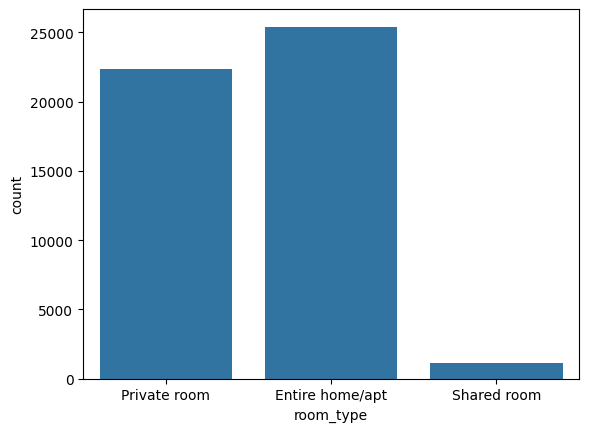

In [37]:
sns.countplot(x = 'room_type',data =df)

In [38]:
df.columns

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')

array([[<Axes: title={'center': 'price'}>,
        <Axes: title={'center': 'minimum_nights'}>],
       [<Axes: title={'center': 'number_of_reviews'}>,
        <Axes: title={'center': 'reviews_per_month'}>],
       [<Axes: title={'center': 'calculated_host_listings_count'}>,
        <Axes: title={'center': 'availability_365'}>]], dtype=object)

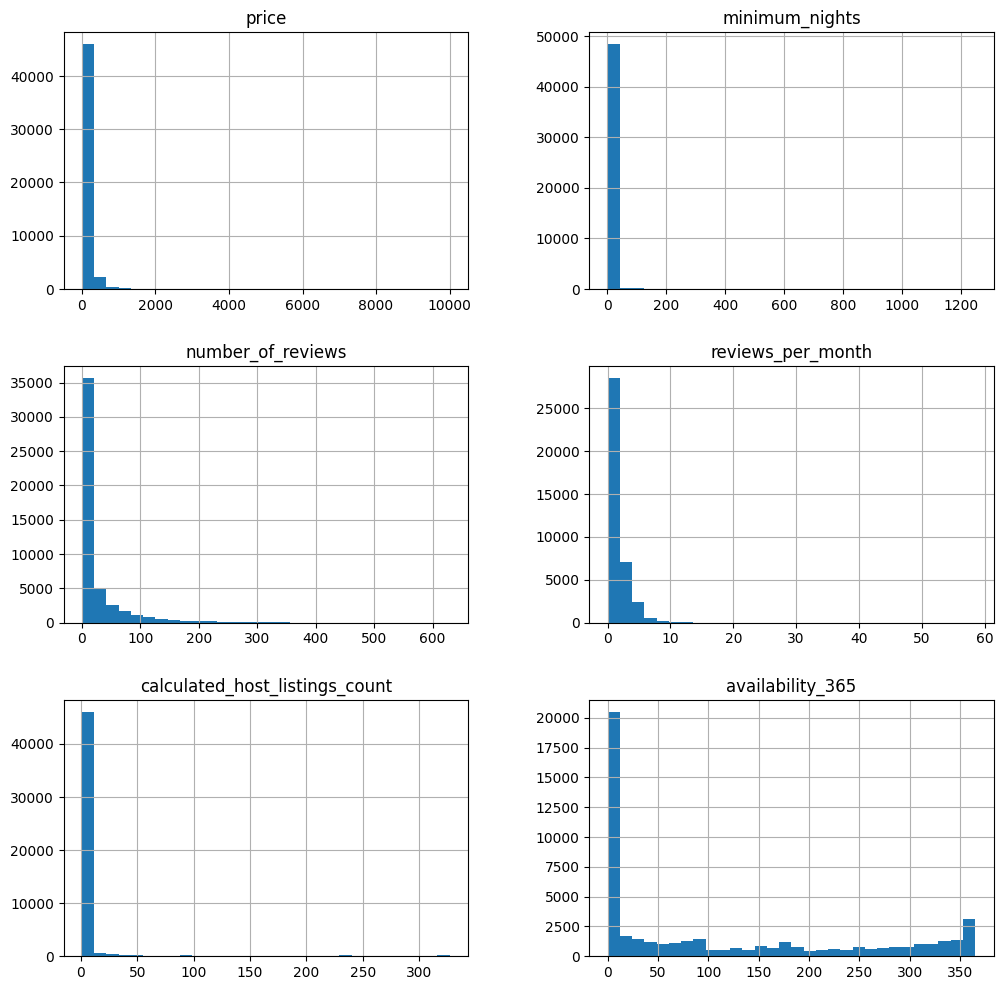

In [39]:
numrical_cols = ['price','minimum_nights','number_of_reviews','reviews_per_month','calculated_host_listings_count','availability_365']

df[numrical_cols].hist(bins = 30,figsize = (12,12))

<Axes: xlabel='neighbourhood_group', ylabel='count'>

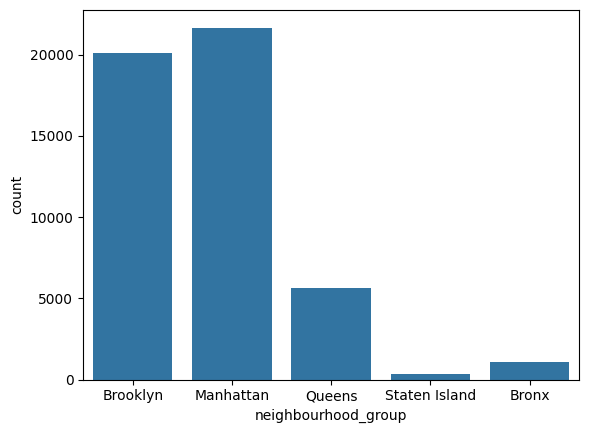

In [40]:
sns.countplot(x = 'neighbourhood_group',data =df)

<Axes: xlabel='room_type', ylabel='price'>

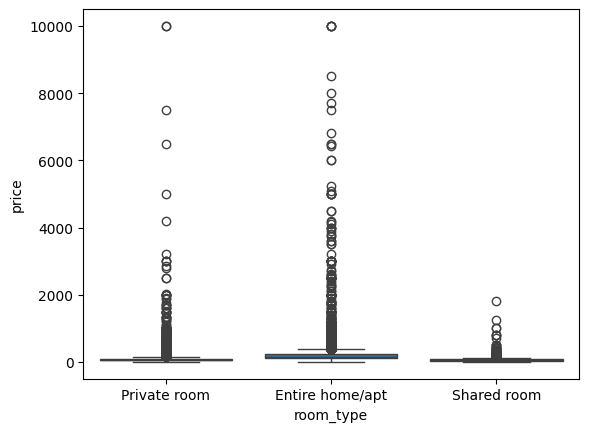

In [41]:
sns.boxplot(x = 'room_type',y = 'price',data = df)

<Axes: >

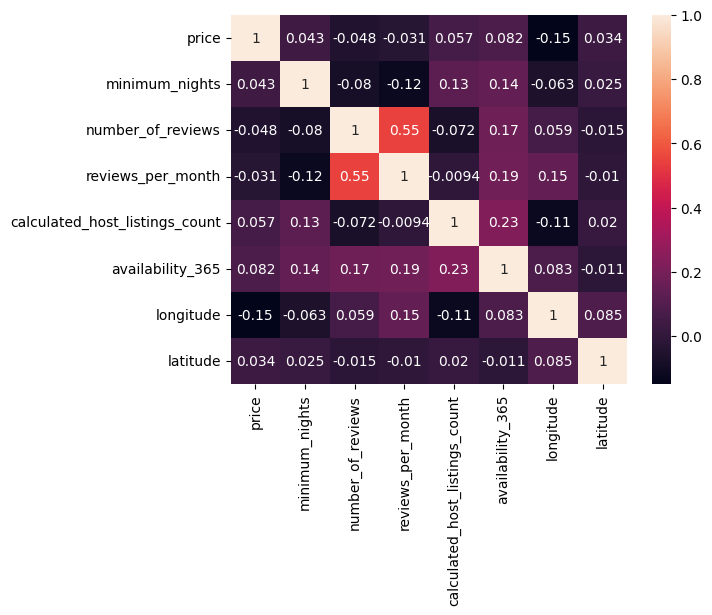

In [42]:
corr = df[numrical_cols +['longitude','latitude']].corr()
sns.heatmap(corr,annot =True )

<Axes: xlabel='longitude', ylabel='latitude'>

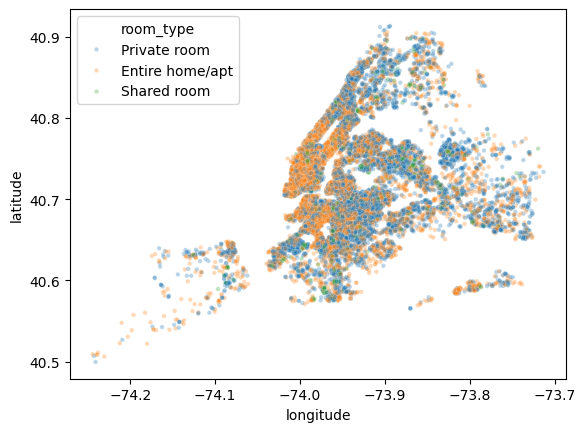

In [43]:
sns.scatterplot(x = 'longitude',y = 'latitude',hue = 'room_type',data = df,alpha = 0.3,s = 10)

In [44]:
df_clean = df.drop(columns = ['id','name','host_id','host_name','last_review'])

In [45]:
df_clean

,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
0,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,0.21,6,365
1,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,0.38,2,355
2,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,1,365
3,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,4.64,1,194
4,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,0.10,1,0
...,...,...,...,...,...,...,...,...,...,...,...
48890,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70,2,0,NaN,2,9
48891,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40,4,0,NaN,2,36
48892,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115,10,0,NaN,1,27
48893,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55,1,0,NaN,6,2


In [46]:
df_clean['reviews_per_month'] = df_clean['reviews_per_month'].fillna(0)

In [47]:
price_cap = df_clean['price'].quantile(0.99)
neights_cap = df_clean['minimum_nights'].quantile(0.99)

df_clean['price'] = df_clean['price'].clip(upper = price_cap)
df_clean['minimum_nights'] = df_clean['minimum_nights'].clip(upper = neights_cap)

In [48]:
x = df.drop(columns = 'room_type')
y = df['room_type']

In [49]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.33, random_state=42, stratify=y)

In [50]:
df_clean[numrical_cols].skew()

,0
price,2.776321
minimum_nights,2.360347
number_of_reviews,3.690635
reviews_per_month,3.300723
calculated_host_listings_count,7.933174
availability_365,0.763408


In [51]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder,StandardScaler,PowerTransformer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer


In [52]:
numarical_cols = ['latitude','longitude','price','minimum_nights','number_of_reviews','reviews_per_month','calculated_host_listings_count','availability_365']
categorical_cols = ['neighbourhood_group','neighbourhood']

In [61]:
numaric_pipeline = Pipeline(steps = [
    ('imputer',SimpleImputer(strategy='median')),
    # ('power',PowerTransformer(method = 'yeo-jenson')),
    ('scaler',StandardScaler())
])

catogarical_pipeline = Pipeline(steps =[
    ('imputer',SimpleImputer(strategy='most_frequent')),
    ('encoder',OneHotEncoder(handle_unknown = 'ignore'))
])

preprocesser = ColumnTransformer(transformers = [
    ('numerical',numaric_pipeline,numarical_cols),
    ('catogarical',catogarical_pipeline,categorical_cols)
])
preprocesser

ColumnTransformer(transformers=[('numerical',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['latitude', 'longitude', 'price',
                                  'minimum_nights', 'number_of_reviews',
                                  'reviews_per_month',
                                  'calculated_host_listings_count',
                                  'availability_365']),
                                ('catogarical',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['neighbourhood_group', 'neighbourhood'])])

In [62]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model  import LogisticRegression
from sklearn.model_selection import cross_val_score

In [63]:
import warnings
warnings.filterwarnings('ignore')

In [66]:
model = {
    'Logistic Regression' :LogisticRegression(class_weight = 'balanced',random_state  = 42),
    'Decision Tree' :DecisionTreeClassifier(class_weight = 'balanced',random_state  = 42),
    'Random Forest' :RandomForestClassifier(class_weight = 'balanced',random_state  = 42),
    'Gradient Boosting' :GradientBoostingClassifier(random_state  = 42)

}

for  name,model in model.items():
  pipe = Pipeline(steps = [('preprocesser',preprocesser),('classifier',model)])

  accuracy = cross_val_score( pipe,x_train,y_train,cv = 3,scoring= 'accuracy')
  f1_micro = cross_val_score( pipe,x_train,y_train,cv = 3,scoring= 'f1_micro')

  print(f'{name} -> accuracy: {accuracy.mean():.3f},f1 {f1_micro.mean():.3f}')

Logistic Regression -> accuracy: 0.633,f1 0.633
Decision Tree -> accuracy: 0.783,f1 0.783
Random Forest -> accuracy: 0.851,f1 0.851
Gradient Boosting -> accuracy: 0.850,f1 0.850


In [71]:
from sklearn.model_selection import RandomizedSearchCV

best_model = Pipeline(steps = [
    ('preprocesser',preprocesser),
    ('classifier',RandomForestClassifier(class_weight='balanced'))
])

param_distributions = {
    'classifier__n_estimators' :[100,200,150,300],
    'classifier__max_depth' :[8,12,15,20,None],
    'classifier__min_samples_split' :[2,5,10]
}

search = RandomizedSearchCV(estimator = best_model,
                            param_distributions = param_distributions,
                            n_iter = 10,
                            cv = 3,
                            scoring = 'f1_micro',
                            random_state = 42)
search.fit(x_train,y_train)

RandomizedSearchCV(cv=3,
                   estimator=Pipeline(steps=[('preprocesser',
                                              ColumnTransformer(transformers=[('numerical',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('scaler',
                                                                                                StandardScaler())]),
                                                                               ['latitude',
                                                                                'longitude',
                                                                                'price',
                                                                                'minimum_nights',
                                                                                'number_of_reviews',
                                                                                'reviews_per_month',
                                                                                'calculated_host_listings_count',
                                                                                'availability_365']),
                                                                              ('cat...
                                                                                                SimpleImputer(strategy='most_frequent')),
                                                                                               ('encoder',
                                                                                                OneHotEncoder(handle_unknown='ignore'))]),
                                                                               ['neighbourhood_group',
                                                                                'neighbourhood'])])),
                                             ('classifier',
                                              RandomForestClassifier(class_weight='balanced'))]),
                   param_distributions={'classifier__max_depth': [8, 12, 15, 20,
                                                                  None],
                                        'classifier__min_samples_split': [2, 5,
                                                                          10],
                                        'classifier__n_estimators': [100, 200,
                                                                     150,
                                                                     300]},
                   random_state=42, scoring='f1_micro')

In [73]:
print('best_parameter:' ,search.best_params_ )
print('best cv micro -f1:' ,search.best_score_ )


best_parameter: {'classifier__n_estimators': 200, 'classifier__min_samples_split': 10, 'classifier__max_depth': None}
best cv micro -f1: 0.8512469247129014


In [78]:
from sklearn.metrics import f1_score, confusion_matrix,accuracy_score
best_pipeline = search.best_estimator_
y_pred = search.predict(x_test)
print(f'f1_score{f1_score(y_test, y_pred, average = 'macro')}')
print(f'accuracy_score{accuracy_score(y_test, y_pred)}')

f1_score0.7357181536525944
accuracy_score0.8558502726822013


<Axes: >

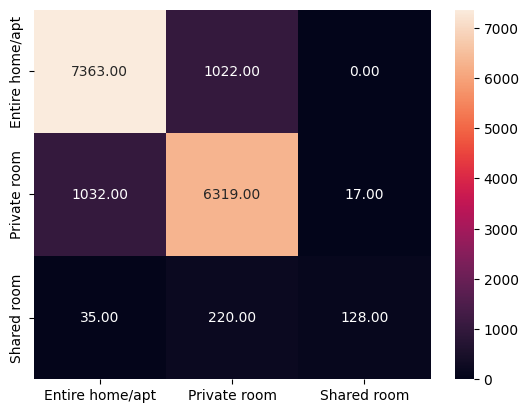

In [80]:
sns.heatmap(confusion_matrix(y_test,y_pred),annot = True,fmt = '.2f',
            xticklabels = best_pipeline.classes_ ,yticklabels = best_pipeline.classes_)

In [81]:
import joblib
joblib.dump(best_pipeline,'model_pipeline.pkl')

['model_pipeline.pkl']